# รวมทะเบียนตัวอย่างซากดึกดำบรรพ์กับแหล่งซากดึกดำบรรพ์

**เป้าหมาย**: เชื่อมตัวอย่างแต่ละชิ้นใน `data/0301010101_fossil_list-31072567.csv` (8,521 ชิ้น ไม่มีพิกัด)
เข้ากับแหล่งใน `data/dmr_fossil_sites/fossil_sites.geojson` (518 แหล่ง มีพิกัด) เพื่อให้ตัวอย่างมีตำแหน่งและบริบทธรณีวิทยา

ทั้งสองชุด**ไม่มีคีย์ร่วม** (ทะเบียนไม่มีรหัสแหล่ง) จึงใช้ชื่อเขตการปกครองแทน ทดลอง 5 วิธี

| วิธี | คีย์ | หมายเหตุ |
|---|---|---|
| A | จังหวัด + อำเภอ + ตำบล | ตรงตัว (หลังทำความสะอาดคีย์) |
| B | จังหวัด + อำเภอ | ตรงตัว |
| C | จังหวัด | ตรงตัว |
| D | Fuzzy | จับคู่แบบลำดับชั้น จังหวัด → อำเภอ → ตำบล ยอมให้สะกดต่างได้ และเทียบกับชื่อแหล่ง/สถานที่เมื่อชื่ออำเภอไม่ตรง |
| (A→B→C) | Exact cascade | ใช้เป็นตัวเทียบ: ลอง A ก่อน ไม่เจอค่อยถอยไป B แล้ว C (แยกผลของ "การถอย" ออกจากผลของ "fuzzy") |

การ join ด้วยชื่อเขตเป็น **many-to-many** (อำเภอเดียวมีหลายแหล่ง) ทุกวิธีจึงได้ "แหล่งผู้สมัคร" หลายแห่งต่อตัวอย่าง
ต้อง**จัดอันดับ**ผู้สมัครด้วยความเข้ากันได้ของเนื้อหา (ชนิดซากในชื่อ/คำบรรยายแหล่ง, กลุ่มซาก, ความใกล้เคียงของชื่อเขต) แล้วเลือกอันดับ 1

**วัดผลอย่างไร (ไม่มีคำตอบจริง)**: สร้าง *silver labels* จากตัวอย่างที่ชื่อสกุลละติน (เช่น *Phuwiangosaurus*)
ปรากฏในคำบรรยายแหล่ง (`FOS_DES_TH`) ในจังหวัดเดียวกัน แล้ววัดว่าแต่ละวิธีเลือกแหล่งถูกบ่อยแค่ไหน
ตัวจัดอันดับ**ไม่ใช้ชื่อละติน** เพื่อไม่ให้รู้คำตอบล่วงหน้า

In [1]:
import csv
import io
import re
import unicodedata
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from rapidfuzz import fuzz, process

DATA = Path("../data")
OUT = DATA / "processed"
OUT.mkdir(exist_ok=True)

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40, "display.max_colwidth", 50, "display.width", 160)
INK, MUTED = "#52514e", "#8a8984"
METHOD_COLOR = {"A": "#86b6ef", "B": "#5598e7", "C": "#256abf", "A→B→C": "#8a8984", "D": "#eb6834"}

## 0. ฟังก์ชันช่วย: โหลดและทำความสะอาดข้อมูล

- `clean_th`, `na_placeholders`, `norm_*`: ปรับข้อความไทยและสร้างคีย์เขตการปกครองสำหรับ join
- `read_fossil_list` / `load_fossil_list`: อ่านทะเบียนตัวอย่าง ซ่อม 3 ระเบียนที่ส่งออกผิด และทำความสะอาด
- `load_sites`: อ่านแหล่งซากดึกดำบรรพ์ (GeoJSON) พร้อมแฟล็กกลุ่มซากแบบ boolean

In [2]:
GROUP_ORDER = ["Vertebrate", "Invertebrate", "Plant", "Trace fossil", "Other"]
GR_FLAGS = {"FOS_GR_1": "Vertebrate", "FOS_GR_2": "Invertebrate", "FOS_GR_3": "Plant", "FOS_GR_4": "Trace fossil", "FOS_GR_5": "Other"}
PLACEHOLDERS = {"", "ไม่ระบุ", "N/A", "-", "รอการตรวจสอบ", "No data", "no data"}
# typos seen in the data -> canonical spelling
DISTRICT_FIX = {"เมืองกาฬสินธ์": "เมืองกาฬสินธุ์", "เมืองสตูน": "เมืองสตูล", "บางกลำ่": "บางกล่ำ", "กันตรัง": "กันตัง"}


def clean_th(s):
    # NFC, decomposed sara am ('ํา') -> 'ำ', collapse whitespace.
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize("NFC", s).replace("ํา", "ำ")
    s = re.sub(r"\s+", " ", s).strip()
    # ตัดสระบน/ล่างหรือวรรณยุกต์ที่ค้างอยู่หน้าข้อความ (ข้อความไทยขึ้นต้นด้วยตัวเหล่านี้ไม่ได้) เช่น '์N/A' -> 'N/A'
    return re.sub(r"^[ัิ-ฺ็-๎]+", "", s)


def na_placeholders(series):
    return series.map(lambda v: pd.NA if (pd.isna(v) or v in PLACEHOLDERS) else v)


def norm_province(p):
    if not isinstance(p, str):
        return pd.NA
    return re.sub(r"^(จังหวัด|จ\.)\s*", "", p)


def norm_district(province, district):
    # Join key for district: drop prefix, fix known typos, bare 'เมือง' -> 'เมือง<province>'.
    if not isinstance(district, str):
        return pd.NA
    d = re.sub(r"^(กิ่งอำเภอ|อำเภอ|อ\.)\s*", "", district)
    d = DISTRICT_FIX.get(d, d)
    if d == "เมือง" and isinstance(province, str):
        d = "เมือง" + province
    return d


def norm_tambon(t):
    if not isinstance(t, str):
        return pd.NA
    return re.sub(r"^(ตำบล|ต\.)\s*", "", t)

In [3]:
def read_fossil_list(path):
    # Read the register, re-attaching record tails that the export pushed onto their own quoted line.
    rows = list(csv.reader(io.StringIO(path.read_text(encoding="utf-8-sig"))))
    header, fixed, repaired = rows[0], [], []
    for r in rows[1:]:
        if r[0].strip().isdigit() or not fixed:
            fixed.append(r)
            continue
        spill = next(csv.reader([r[0]]))
        prev = fixed[-1]
        k = max(i for i, v in enumerate(prev) if v.strip())
        prev[k] += spill[0]
        prev[k + 1:k + len(spill)] = spill[1:]
        assert len(prev) == len(header), prev
        repaired.append(prev[0])
    return pd.DataFrame(fixed, columns=header), repaired


def load_fossil_list(path):
    raw, repaired = read_fossil_list(path)
    fl = raw.rename(columns={"tambom": "tambon"}).apply(lambda c: c.map(clean_th))
    for c in ["sci_name", "com_name", "f_group", "f_type", "f_part", "dis_name", "province", "district", "tambon", "regis_code"]:
        fl[c] = na_placeholders(fl[c])
    fl["province"] = fl.province.map(norm_province)
    fl["f_group"] = fl.f_group.replace({"Plant fossil": "Plant"}).str.replace(r"^Other.*", "Other", regex=True)

    # fill a missing province from the district when that district name occurs in only one province
    d2p = fl.dropna(subset=["province", "district"]).groupby("district").province.unique()
    unique_d2p = {d: p[0] for d, p in d2p.items() if len(p) == 1 and d != "เมือง"}
    fl["province_inferred"] = fl.province.isna() & fl.district.map(unique_d2p).notna()
    fl.loc[fl.province_inferred, "province"] = fl.loc[fl.province_inferred, "district"].map(unique_d2p)

    fl["district_key"] = [norm_district(p, d) for p, d in zip(fl.province, fl.district)]
    fl["tambon_key"] = fl.tambon.map(norm_tambon)
    fl["genus"] = (fl.sci_name.where(~fl.sci_name.fillna("N/A").str.startswith("N/A"))
                   .str.replace(r"^[?\s]*(cf\.|aff\.)?\s*", "", regex=True).str.split().str[0])
    assert fl.fossil_id.is_unique
    return fl, repaired

In [4]:
def load_sites(path):
    sites = gpd.read_file(path)
    for c in sites.columns:
        if c != "geometry" and (sites[c].dtype == object or str(sites[c].dtype) == "str"):
            sites[c] = sites[c].map(clean_th).replace({"": pd.NA, "<Null>": pd.NA})
    for col, g in GR_FLAGS.items():
        sites[g] = sites[col].notna() & sites[col].ne("N")
    sites["OBJECTID"] = sites.OBJECTID.astype(int)
    sites["province_key"] = sites.PROVINCE.map(norm_province)
    sites["district_key"] = [norm_district(p, d) for p, d in zip(sites.province_key, sites.DISTRICT)]
    sites["tambon_key"] = sites.TAMBON.map(norm_tambon)
    sites["longitude"] = sites.geometry.x
    sites["latitude"] = sites.geometry.y
    return sites

In [5]:
fl, repaired = load_fossil_list(DATA / "0301010101_fossil_list-31072567.csv")
sites = load_sites(DATA / "dmr_fossil_sites" / "fossil_sites.geojson")
N = len(fl)
print(f"ตัวอย่าง {N:,} ชิ้น (ซ่อม {len(repaired)} ระเบียน) | แหล่ง {len(sites)} แห่ง")

ตัวอย่าง 8,521 ชิ้น (ซ่อม 3 ระเบียน) | แหล่ง 518 แห่ง


## 1. เตรียมคีย์สำหรับ join

ทำความสะอาดชื่อเขตการปกครองของทั้งสองชุดด้วยกฎเดียวกัน (ฟังก์ชันในส่วนที่ 0)
- ปรับข้อความไทยให้เป็นรูปเดียวกัน, ตัดคำนำหน้า `จังหวัด` / `อำเภอ` / `ตำบล`, แปลง `ไม่ระบุ` เป็นค่าว่าง
- `เมือง` → `เมือง<จังหวัด>`, แก้คำผิดที่พบ (`เมืองกาฬสินธ์`, `เมืองสตูน`, `กันตรัง`)
- เติมจังหวัดของตัวอย่างจากชื่ออำเภอที่มีในจังหวัดเดียว

ตารางด้านล่างเทียบจำนวนตัวอย่างที่ join ตรงตัวได้ ระหว่าง "ก่อน" กับ "หลัง" ทำความสะอาด

In [6]:
raw = pd.read_csv(DATA / "0301010101_fossil_list-31072567.csv", dtype=str, encoding="utf-8-sig")
raw_keys = raw[["province", "district", "tambom"]].apply(lambda c: c.str.strip())
site_raw = sites[["PROVINCE", "DISTRICT", "TAMBON"]].apply(lambda c: c.str.strip())

LEVELS = {"A": ["province", "district", "tambon"], "B": ["province", "district"], "C": ["province"]}
clean_left = fl[["province", "district_key", "tambon_key"]].set_axis(["province", "district", "tambon"], axis=1)
clean_right = sites[["province_key", "district_key", "tambon_key"]].set_axis(["province", "district", "tambon"], axis=1)
raw_left = raw_keys.set_axis(["province", "district", "tambon"], axis=1)
raw_right = site_raw.set_axis(["province", "district", "tambon"], axis=1)


def n_matched(left, right, keys):
    right_keys = set(map(tuple, right[keys].dropna().values))
    return sum(tuple(r) in right_keys for r in left[keys].values)


pd.DataFrame({
    "คีย์": [" + ".join(v) for v in LEVELS.values()],
    "ก่อนทำความสะอาด": [n_matched(raw_left, raw_right, k) for k in LEVELS.values()],
    "หลังทำความสะอาด": [n_matched(clean_left, clean_right, k) for k in LEVELS.values()],
}, index=list(LEVELS)).assign(เพิ่มขึ้น=lambda d: d["หลังทำความสะอาด"] - d["ก่อนทำความสะอาด"])

,คีย์,ก่อนทำความสะอาด,หลังทำความสะอาด,เพิ่มขึ้น
A,province + district + tambon,3199,3750,551
B,province + district,5713,6341,628
C,province,7331,7853,522


## 2. วิธี A, B, C: Exact merge

ผลลัพธ์อยู่ในรูป**ตารางคู่ผู้สมัคร** `(fossil_id, OBJECTID)` หนึ่งแถวต่อหนึ่งคู่ ตัวอย่างหนึ่งชิ้นอาจมีหลายแถว

In [7]:
SITE_KEYS = sites[["OBJECTID", "province_key", "district_key", "tambon_key"]]
SPEC_KEYS = fl[["fossil_id", "province", "district_key", "tambon_key"]].rename(columns={"province": "province_key"})
KEYCOLS = {"A": ["province_key", "district_key", "tambon_key"], "B": ["province_key", "district_key"], "C": ["province_key"]}
LEVEL_NAME = {"A": "tambon", "B": "district", "C": "province"}


def exact_candidates(method):
    keys = KEYCOLS[method]
    m = SPEC_KEYS.dropna(subset=keys).merge(SITE_KEYS.dropna(subset=keys), on=keys, how="inner")
    return m[["fossil_id", "OBJECTID"]].assign(match_level=LEVEL_NAME[method])


cands = {m: exact_candidates(m) for m in "ABC"}

# cascade: ใช้ระดับที่ละเอียดที่สุดที่เจอ
taken, parts = set(), []
for m in "ABC":
    c = cands[m][~cands[m].fossil_id.isin(taken)]
    parts.append(c)
    taken |= set(c.fossil_id)
cands["A→B→C"] = pd.concat(parts, ignore_index=True)

for m, c in cands.items():
    k = c.groupby("fossil_id").size()
    print(f"{m:6s} แถวหลัง merge {len(c):>8,} | ตัวอย่างที่ match {k.size:>5,} ({k.size / N:5.1%}) | ผู้สมัครต่อชิ้น เฉลี่ย {k.mean():5.1f} สูงสุด {k.max()}")

A      แถวหลัง merge   12,794 | ตัวอย่างที่ match 3,750 (44.0%) | ผู้สมัครต่อชิ้น เฉลี่ย   3.4 สูงสุด 11
B      แถวหลัง merge   38,429 | ตัวอย่างที่ match 6,341 (74.4%) | ผู้สมัครต่อชิ้น เฉลี่ย   6.1 สูงสุด 26
C      แถวหลัง merge  160,332 | ตัวอย่างที่ match 7,853 (92.2%) | ผู้สมัครต่อชิ้น เฉลี่ย  20.4 สูงสุด 57
A→B→C  แถวหลัง merge   50,264 | ตัวอย่างที่ match 7,853 (92.2%) | ผู้สมัครต่อชิ้น เฉลี่ย   6.4 สูงสุด 57


ยิ่งคีย์หยาบ ยิ่ง match ได้มาก แต่**จำนวนแถวระเบิด**: วิธี C ให้ผู้สมัครเฉลี่ยหลายสิบแหล่งต่อชิ้น
ซึ่งแทบไม่ได้บอกว่าตัวอย่างมาจากแหล่งไหน

## 3. วิธี D: Fuzzy hierarchical merge

ทำทีละระดับภายในขอบเขตของระดับก่อนหน้า (ไม่เทียบข้ามจังหวัด)
1. **จังหวัด**: ตรงตัว หรือ fuzzy ≥ 90
2. **อำเภอ** (เฉพาะในจังหวัดนั้น): fuzzy ≥ 85
3. **ตำบล** (เฉพาะในอำเภอนั้น): fuzzy ≥ 75 โดยเทียบทั้งชื่อเต็มและชื่อที่ตัด "บ้าน" ออก (`บ้านนาชะอัง` ≈ `นาชะอัง`)
4. **ชื่อสถานที่**: ถ้าระดับใดไม่ตรง ลองหาข้อความอำเภอ/ตำบลของตัวอย่างในชื่อแหล่ง (`NAME_TH`) หรือ `LOCALITY`
   ด้วย partial match ≥ 90 เช่น ตัวอย่าง "ภูเวียง" → "แหล่งขุดค้นไดโนเสาร์**ภูเวียง**หลุมขุดค้นที่ 3"
   (อำเภอภูเวียงถูกแยกเป็นอำเภอเวียงเก่า ชื่ออำเภอจึงไม่ตรงกัน)
5. ไม่เจอที่ระดับละเอียด → ถอยกลับไปใช้แหล่งทั้งหมดของระดับที่ match ล่าสุด

คะแนน fuzzy ใช้ `rapidfuzz.fuzz.ratio` (0–100)

In [8]:
def strip_ban(s):
    return re.sub(r"^บ้าน", "", s)


def name_sim(a, b, **_):
    # ความคล้ายของชื่อเขต: เทียบทั้งชื่อเต็มและชื่อที่ตัดคำว่า 'บ้าน'
    if not isinstance(a, str) or not isinstance(b, str):
        return 0.0
    return max(fuzz.ratio(a, b), fuzz.ratio(strip_ban(a), strip_ban(b)))


sites["loc_text"] = (sites.NAME_TH.fillna("") + " " + sites.LOCALITY.fillna("")).str.strip()
SITES_BY_PROV = {p: g for p, g in sites.groupby("province_key")}


def locality_hits(S, texts, t_loc):
    for t in texts:
        if isinstance(t, str) and len(t) >= 3:
            hit = S[[fuzz.partial_ratio(t, x) >= t_loc for x in S.loc_text]]
            if len(hit):
                return hit
    return None


def fuzzy_match(prov, dist, tamb, t_prov=90, t_dist=85, t_tamb=75, t_loc=90):
    # คืน (site_ids, match_level, รายละเอียดที่จับคู่)
    if not isinstance(prov, str):
        return [], "none", ""
    P = prov if prov in SITES_BY_PROV else (process.extractOne(prov, list(SITES_BY_PROV), scorer=fuzz.ratio, score_cutoff=t_prov) or [None])[0]
    if P is None:
        return [], "none", ""
    S = SITES_BY_PROV[P]
    D = None
    if isinstance(dist, str):
        best = process.extractOne(dist, S.district_key.dropna().unique(), scorer=name_sim, score_cutoff=t_dist)
        D = best[0] if best else None
    if D is not None:
        SD = S[S.district_key.eq(D)]
        if isinstance(tamb, str):
            bt = process.extractOne(tamb, SD.tambon_key.dropna().unique(), scorer=name_sim, score_cutoff=t_tamb)
            if bt:
                return SD.loc[SD.tambon_key.eq(bt[0]), "OBJECTID"].tolist(), "tambon", f"{tamb}→{bt[0]} ({bt[1]:.0f})"
        hit = locality_hits(SD, [tamb], t_loc)
        if hit is not None:
            return hit.OBJECTID.tolist(), "locality", f"{tamb}~ชื่อแหล่ง"
        return SD.OBJECTID.tolist(), "district", f"{dist}→{D}"
    hit = locality_hits(S, [dist, tamb], t_loc)
    if hit is not None:
        return hit.OBJECTID.tolist(), "locality", f"{dist}/{tamb}~ชื่อแหล่ง"
    return S.OBJECTID.tolist(), "province", f"{prov}→{P}"


def fuzzy_candidates(**thresholds):
    sig = SPEC_KEYS[["province_key", "district_key", "tambon_key"]].drop_duplicates()
    rows = []
    for p, d, t in sig.itertuples(index=False):
        ids, level, note = fuzzy_match(p, d, t, **thresholds)
        rows += [(p, d, t, i, level, note) for i in ids]
    pairs = pd.DataFrame(rows, columns=["province_key", "district_key", "tambon_key", "OBJECTID", "match_level", "fuzzy_note"])
    return SPEC_KEYS.merge(pairs, on=["province_key", "district_key", "tambon_key"], how="inner")[["fossil_id", "OBJECTID", "match_level", "fuzzy_note"]]


cands["D"] = fuzzy_candidates()
k = cands["D"].groupby("fossil_id").size()
print(f"D      แถวหลัง merge {len(cands['D']):>8,} | ตัวอย่างที่ match {k.size:>5,} ({k.size / N:5.1%}) | ผู้สมัครต่อชิ้น เฉลี่ย {k.mean():5.1f}")
cands["D"].drop_duplicates("fossil_id").match_level.value_counts().rename("ตัวอย่าง (ระดับที่ match)").to_frame().T

D      แถวหลัง merge   44,906 | ตัวอย่างที่ match 7,853 (92.2%) | ผู้สมัครต่อชิ้น เฉลี่ย   5.7


match_level,tambon,district,province,locality
ตัวอย่าง (ระดับที่ match),3811,2522,1106,414


ตัวอย่างคู่ที่ fuzzy ช่วยแก้ (ชื่อไม่ตรงตัวแต่ใกล้เคียง หรือเจอในชื่อแหล่ง)

In [9]:
fz = (cands["D"].drop_duplicates("fossil_id").merge(fl[["fossil_id", "province", "district", "tambon"]], on="fossil_id")
      .loc[lambda d: d.match_level.isin(["tambon", "locality"]) & d.fuzzy_note.str.contains(r"\(\d+\)|~", regex=True)])
fz = fz[~fz.fuzzy_note.str.contains(r"\(100\)")]
fz.groupby(["province", "district", "tambon", "match_level", "fuzzy_note"], dropna=False).size().rename("ตัวอย่าง").sort_values(ascending=False).head(20).to_frame()

ตัวอย่าง
province      district    tambon      match_level fuzzy_note                             
กาฬสินธุ์     ภูน้อย      คำม่วง      locality    ภูน้อย/คำม่วง~ชื่อแหล่ง             152
ขอนแก่น       ภูเวียง     NaN         locality    ภูเวียง/nan~ชื่อแหล่ง               106
                          ในเมือง     locality    ภูเวียง/ในเมือง~ชื่อแหล่ง            63
                          กุดหว้า     locality    ภูเวียง/กุดหว้า~ชื่อแหล่ง            42
นครพนม        ท่าอุเทน    พนม         tambon      พนม→พนอม (86)                        29
ขอนแก่น       ภูเวียง     ภูเวียง     locality    ภูเวียง/ภูเวียง~ชื่อแหล่ง            28
เลย           บ้านน้ำสวย  นาด้วง      locality    บ้านน้ำสวย/นาด้วง~ชื่อแหล่ง           4
มุกดาหาร      หนองสูง     บ้านคำพอก   locality    บ้านคำพอก~ชื่อแหล่ง                   4
กาฬสินธุ์     กุฉินารายณ์ เหล่าใหญ๋   tambon      เหล่าใหญ๋→เหล่าใหญ่ (89)              3
พังงา         เกาะยาว     แหลมไทร     locality    แหลมไทร~ชื่อแหล่ง                     3
กระบี่        อ่าวลึก     อ่าวน้ำ     locality    อ่าวน้ำ~ชื่อแหล่ง                     2
นครศรีธรรมราช ร่อนพิพูลย์ ร่อนพิพูลย์ tambon      ร่อนพิพูลย์→ร่อนพิบูลย์ (91)          2
นครราชสีมา    วังน้ำเขียว วังหมี      locality    วังน้ำเขียว/วังหมี~ชื่อแหล่ง          1
กาญจนบุรี     ทองผาภูมิ   หินดาต      tambon      หินดาต→หินดาด (83)                    1
กาฬสินธุ์     นาไคร้      กุฉินารายณ์ locality    นาไคร้/กุฉินารายณ์~ชื่อแหล่ง          1
พังงา         เกาะยาวน้อย แหลมไทร     locality    เกาะยาวน้อย/แหลมไทร~ชื่อแหล่ง         1
              เมืองพังงา  ไทยช้าง     tambon      ไทยช้าง→ท้ายช้าง (80)                 1
กาฬสินธุ์     คำม่วง      สร้างแข้    locality    สร้างแข้~ชื่อแหล่ง                    1
ลำปาง         เเม่เมาะ    แม่เมาะ     locality    เเม่เมาะ/แม่เมาะ~ชื่อแหล่ง            1
              แม่เมาะ     ลี้         locality    ลี้~ชื่อแหล่ง                         1

### เลือก threshold ของตำบล

ลองไล่ค่า threshold ของตำบลตั้งแต่ 50 ถึง 100 ดูว่าได้คู่ใหม่จากการสะกดผิดจริง หรือเริ่มจับคู่ผิดตำบล

,จังหวัด,อำเภอ,ตำบล (ตัวอย่าง),ตำบล (แหล่ง) ใกล้สุด,score,ตัวอย่าง
84,เลย,เอราวัณ,ทรัพย์ไพรวัลย์,ทรัพย์ไพวัลย์,96.3,1
52,สตูล,เมืองสตูล,เกาะตรุเตา,เกาะตะรุเตา,95.2,1
33,นครศรีธรรมราช,ร่อนพิบูลย์,ร่อนพิพูลย์,ร่อนพิบูลย์,90.9,2
6,กาฬสินธุ์,กุฉินารายณ์,เหล่าใหญ๋,เหล่าใหญ่,88.9,3
27,นครพนม,ท่าอุเทน,พนม,พนอม,85.7,29
2,กาญจนบุรี,ทองผาภูมิ,หินดาต,หินดาด,83.3,1
38,พังงา,เมืองพังงา,ไทยช้าง,ท้ายช้าง,80.0,1
5,กาญจนบุรี,เมืองกาญจนบุรี,วังตั้ง,วังด้ง,76.9,1
62,เพชรบุรี,เขาย้อย,ทับดาว,ทับคาง,66.7,1
36,พังงา,เกาะยาว,เกาะยาวใหญ่,เกาะยาวน้อย,63.6,7


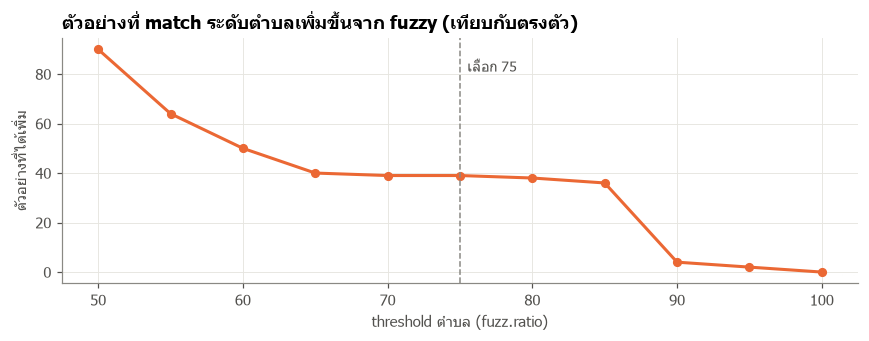

In [10]:
sig = SPEC_KEYS.dropna(subset=["province_key", "district_key", "tambon_key"]).groupby(["province_key", "district_key", "tambon_key"]).size()
pairs = []
for (p, d, t), n in sig.items():
    S = SITES_BY_PROV.get(p)
    if S is None:
        continue
    best = process.extractOne(d, S.district_key.dropna().unique(), scorer=name_sim, score_cutoff=85)
    if not best:
        continue
    tambs = S.loc[S.district_key.eq(best[0]), "tambon_key"].dropna().unique()
    bt = process.extractOne(t, tambs, scorer=name_sim)
    if bt and bt[1] < 100:
        pairs.append((p, best[0], t, bt[0], round(bt[1], 1), n))
near = pd.DataFrame(pairs, columns=["จังหวัด", "อำเภอ", "ตำบล (ตัวอย่าง)", "ตำบล (แหล่ง) ใกล้สุด", "score", "ตัวอย่าง"]).sort_values("score", ascending=False)
display(near.query("score >= 50").head(25))

th = np.arange(50, 101, 5)
gain = [near.loc[near.score >= t, "ตัวอย่าง"].sum() for t in th]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(th, gain, color=METHOD_COLOR["D"], lw=2, marker="o", ms=5)
ax.axvline(75, color=MUTED, ls="--", lw=1)
ax.text(75.5, max(gain) * 0.9, "เลือก 75", color=INK, fontsize=9)
ax.set_xlabel("threshold ตำบล (fuzz.ratio)")
ax.set_ylabel("ตัวอย่างที่ได้เพิ่ม")
ax.set_title("ตัวอย่างที่ match ระดับตำบลเพิ่มขึ้นจาก fuzzy (เทียบกับตรงตัว)")
plt.tight_layout()

ช่วง ≥ 75 เป็นการสะกดผิดหรือวรรณยุกต์ต่างจริง (`หินดาต`/`หินดาด`, `เหล่าใหญ๋`/`เหล่าใหญ่`, `ไทยช้าง`/`ท้ายช้าง`, `วังตั้ง`/`วังด้ง`)
ส่วนต่ำกว่า 75 เริ่มเป็น**คนละตำบล** (`เกาะยาวใหญ่`/`เกาะยาวน้อย`, `นาบอน`/`นาทัน`) จึงเลือก 75

## 4. จัดอันดับผู้สมัคร

ใช้ตัวจัดอันดับเดียวกันกับทุกวิธี คะแนน 0–1 ต่อคู่ (ตัวอย่าง, แหล่ง)

| องค์ประกอบ | น้ำหนัก | ความหมาย |
|---|---|---|
| `kw` | 0.5 | ชื่อสามัญ/ประเภทของตัวอย่าง (`com_name`, `f_type`) ปรากฏในชื่อหรือคำบรรยายแหล่งไหม (fuzzy partial) เช่น "ไดโนเสาร์", "แบรคิโอพอด" |
| `grp` | 0.3 | แหล่งมีแฟล็กกลุ่มซากเดียวกับตัวอย่าง (Vertebrate / Invertebrate / ...) |
| `adm` | 0.2 | ความใกล้เคียงของชื่ออำเภอและตำบล |

เลือกแหล่งที่คะแนนสูงสุด ถ้าเสมอกันหลายแหล่งจะบันทึกจำนวนที่เสมอ (`n_top`) ไว้ด้วย

In [11]:
def terms_of(row):
    ts = set()
    for v in (row.com_name, row.f_type):
        if isinstance(v, str):
            ts |= {t.strip() for t in v.split("/") if len(t.strip()) >= 3}
    return tuple(sorted(ts))


fl["terms"] = fl.apply(terms_of, axis=1)
sites["content_text"] = (sites.NAME_TH.fillna("") + " " + sites.FOS_DES_TH.fillna(""))
SITE = sites.set_index("OBJECTID")

all_pairs = pd.concat(cands.values(), ignore_index=True)[["fossil_id", "OBJECTID"]].drop_duplicates()
P = all_pairs.merge(fl[["fossil_id", "terms", "f_group", "district_key", "tambon_key"]], on="fossil_id")

# คำนวณบนคู่ (เนื้อหา, แหล่ง) ที่ไม่ซ้ำกันเพื่อความเร็ว
kw_cache = {}
def kw_score(terms, oid):
    key = (terms, oid)
    if key not in kw_cache:
        text = SITE.at[oid, "content_text"]
        kw_cache[key] = max((fuzz.partial_ratio(t, text) for t in terms), default=0) / 100 if text.strip() else 0.0
    return kw_cache[key]


adm_cache = {}
def adm_score(d, t, oid):
    key = (d, t, oid)
    if key not in adm_cache:
        adm_cache[key] = (name_sim(d, SITE.at[oid, "district_key"]) + name_sim(t, SITE.at[oid, "tambon_key"])) / 200
    return adm_cache[key]


P["kw"] = [kw_score(t, o) for t, o in zip(P.terms, P.OBJECTID)]
P["kw"] = P.kw.where(P.kw >= 0.8, 0.0)  # partial match ต่ำกว่า 80 มักเป็นคำบางส่วนที่บังเอิญตรง
P["grp"] = [float(SITE.at[o, g]) if isinstance(g, str) else 0.0 for g, o in zip(P.f_group, P.OBJECTID)]
P["adm"] = [adm_score(d, t, o) for d, t, o in zip(P.district_key, P.tambon_key, P.OBJECTID)]
P["score"] = 0.5 * P.kw + 0.3 * P.grp + 0.2 * P.adm
SCORES = P.set_index(["fossil_id", "OBJECTID"])[["kw", "grp", "adm", "score"]]
print(f"คู่ที่ให้คะแนน {len(P):,} คู่")
SCORES.describe().round(2)

คู่ที่ให้คะแนน 160,332 คู่


,kw,grp,adm,score
count,160332.00,160332.00,160332.00,160332.00
mean,0.37,0.68,0.29,0.45
std,0.48,0.46,0.28,0.34
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.09,0.10
50%,0.00,1.00,0.18,0.35
75%,1.00,1.00,0.46,0.82
max,1.00,1.00,1.00,1.00


## 5. Silver labels สำหรับวัดผล

ดึงชื่อสกุลละตินจาก `FOS_DES_TH` ของแหล่ง ตัวอย่างที่สกุลเดียวกันและอยู่จังหวัดเดียวกันถือว่า "แหล่งที่ถูก" คือแหล่งเหล่านั้น
(ถ้ามีหลายแหล่ง เลือกแหล่งไหนในชุดก็นับว่าถูก)

ข้อจำกัด: ได้เฉพาะตัวอย่างที่จำแนกถึงสกุลและแหล่งที่เขียนชื่อละตินไว้ และเอนไปทาง *Phuwiangosaurus*
จึงรายงานทั้ง **micro** (เฉลี่ยรายชิ้น) และ **macro** (เฉลี่ยราย กลุ่ม สกุล×จังหวัด ให้แต่ละกลุ่มมีน้ำหนักเท่ากัน)

In [12]:
NOT_GENUS = {"Rugosa", "Tabulata", "Productid"}
sites["genera"] = sites.FOS_DES_TH.fillna("").str.findall(r"\b([A-Z][a-z]{3,})\b").map(
    lambda L: {g for g in L if not g.endswith(("idae", "oidea"))} - NOT_GENUS)
genus_sites = sites.explode("genera").dropna(subset=["genera"]).groupby(["genera", "province_key"]).OBJECTID.agg(frozenset)

silver = (fl.dropna(subset=["genus", "province"])
          .assign(true_sites=lambda d: [genus_sites.get((g, p)) for g, p in zip(d.genus, d.province)])
          .dropna(subset=["true_sites"])[["fossil_id", "genus", "province", "true_sites"]])
silver["label_group"] = silver.genus + " | " + silver.province
TRUE = dict(zip(silver.fossil_id, silver.true_sites))
print(f"silver labels {len(silver)} ตัวอย่าง | {silver.label_group.nunique()} กลุ่ม (สกุล×จังหวัด)")
silver.label_group.value_counts().head(12).to_frame("ตัวอย่าง").T

silver labels 957 ตัวอย่าง | 30 กลุ่ม (สกุล×จังหวัด)


label_group,Phuwiangosaurus | กาฬสินธุ์,Phuwiangosaurus | ขอนแก่น,Thaiichthys | กาฬสินธุ์,Posidonomya | สตูล,Ferganoceratodus | กาฬสินธุ์,Siamraptor | นครราชสีมา,Khoratpithecus | พะเยา,Joannites | ลำปาง,Spinomartinia | กระบี่,Basilochelys | มุกดาหาร,Siamosaurus | ขอนแก่น,Paratrachyceras | ลำปาง
ตัวอย่าง,451,213,131,24,23,22,18,8,7,7,7,6


## 6. เปรียบเทียบวิธี

| ตัวชี้วัด | ความหมาย | ดี |
|---|---|---|
| `coverage` | สัดส่วนตัวอย่างที่ได้ผู้สมัครอย่างน้อย 1 แหล่ง | สูง |
| `rows` | แถวหลัง merge (many-to-many) | ต่ำ |
| `cand_mean` | ผู้สมัครเฉลี่ยต่อชิ้นที่ match | ต่ำ |
| `unique_%` | สัดส่วนที่มีผู้สมัครแหล่งเดียว | สูง |
| `group_consistency` | สัดส่วนผู้สมัครที่แฟล็กกลุ่มซากตรงกับตัวอย่าง | สูง |
| `silver_recall` | แหล่งที่ถูกอยู่ในผู้สมัครไหม (ตัวอย่างที่ไม่ match นับเป็นพลาด) | สูง |
| `acc_join` | ความน่าจะเป็นที่เลือกถูกถ้า**สุ่ม**จากผู้สมัคร (= คุณภาพของ join อย่างเดียว) | สูง |
| `acc_ranked` | ความน่าจะเป็นที่**อันดับ 1** ถูกแหล่ง (ถ้าเสมอกัน k แหล่ง นับ 1/k) | สูง |
| `dist_km_median` | ระยะ (กม.) จากแหล่งอันดับ 1 ถึงแหล่งที่ถูกที่ใกล้สุด (silver, มัธยฐาน) | ต่ำ |
| `within_10km` | สัดส่วน silver ที่แหล่งอันดับ 1 อยู่ห่างแหล่งที่ถูกไม่เกิน 10 กม. (ไม่ match = พลาด) | สูง |
| `loc_consistency` | ในตัวอย่างที่บันทึกอำเภอไว้ (และอำเภอนั้นมีแหล่ง) แหล่งอันดับ 1 อยู่ในอำเภอเดียวกัน | สูง |

`acc_ranked` วัดว่า "ตรงแหล่ง" ซึ่งเข้มงวดเกินไปเมื่อหลายแหล่งอยู่ในตำบลเดียวกันและข้อมูลตัวอย่างไม่พอจะแยก
ระยะทางจึงบอกได้ดีกว่าว่าตำแหน่งที่ได้ใช้งานได้จริงไหม และ `loc_consistency` ใช้ตัวอย่างทั้งหมดไม่ใช่แค่ silver

In [13]:
def pick_top(c):
    # อันดับ 1 ต่อชิ้น พร้อมจำนวนที่เสมอกัน
    s = c[["fossil_id", "OBJECTID"]].join(SCORES, on=["fossil_id", "OBJECTID"])
    s["best"] = s.groupby("fossil_id").score.transform("max")
    top = s[np.isclose(s.score, s.best)]
    return top


XY = sites.to_crs(32647).geometry
XY = pd.DataFrame({"x": XY.x.values, "y": XY.y.values}, index=sites.OBJECTID)
SPEC_DIST = fl.set_index("fossil_id")[["province", "district_key"]]
SITE_DISTRICTS = set(zip(sites.province_key, sites.district_key))


def min_km(oid, targets):
    p = XY.loc[oid]
    t = XY.loc[list(targets)]
    return float(np.sqrt((t.x - p.x) ** 2 + (t.y - p.y) ** 2).min() / 1000)


def evaluate(c):
    k = c.groupby("fossil_id").size()
    cg = c.merge(fl[["fossil_id", "f_group"]], on="fossil_id")
    cg["ok_grp"] = [bool(SITE.at[o, g]) if isinstance(g, str) else False for g, o in zip(cg.f_group, cg.OBJECTID)]
    cand_sets = c.groupby("fossil_id").OBJECTID.agg(set)
    top_sets = pick_top(c).groupby("fossil_id").OBJECTID.agg(set)

    per = []
    for fid, true in TRUE.items():
        cs, ts = cand_sets.get(fid, set()), top_sets.get(fid, set())
        dist = np.mean([min_km(o, true) for o in ts]) if ts else np.nan
        per.append((fid, bool(cs & true), len(cs & true) / len(cs) if cs else 0.0, len(ts & true) / len(ts) if ts else 0.0, dist))
    per = pd.DataFrame(per, columns=["fossil_id", "recall", "acc_join", "acc_ranked", "dist_km"]).merge(silver[["fossil_id", "label_group"]], on="fossil_id")
    per["within_10km"] = per.dist_km.le(10)
    macro = per.groupby("label_group")[["recall", "acc_join", "acc_ranked", "within_10km"]].mean().mean()

    # ความสอดคล้องกับอำเภอที่ตัวอย่างบันทึกไว้ (ค่าคาดหวังเมื่อเสมอกัน)
    top = pick_top(c)[["fossil_id", "OBJECTID"]]
    top = top.join(SPEC_DIST, on="fossil_id")
    top = top[[(p, d) in SITE_DISTRICTS for p, d in zip(top.province, top.district_key)]]
    top["same_district"] = [SITE.at[o, "district_key"] == d for o, d in zip(top.OBJECTID, top.district_key)]
    loc_cons = top.groupby("fossil_id").same_district.mean().mean()
    return {
        "coverage": k.size / N, "rows": len(c), "cand_mean": k.mean(), "unique_%": (k == 1).mean(),
        "group_consistency": cg.groupby("fossil_id").ok_grp.mean().mean(),
        "silver_recall": per.recall.mean(), "acc_join": per.acc_join.mean(), "acc_ranked": per.acc_ranked.mean(),
        "macro_recall": macro.recall, "macro_acc_join": macro.acc_join, "macro_acc_ranked": macro.acc_ranked,
        "dist_km_median": per.dist_km.median(), "within_10km": per.within_10km.mean(), "macro_within_10km": macro.within_10km,
        "loc_consistency": loc_cons,
    }


order = ["A", "B", "C", "A→B→C", "D"]
results = pd.DataFrame({m: evaluate(cands[m]) for m in order}).T
pct = [c for c in results.columns if c not in ("rows", "cand_mean", "dist_km_median")]
results.style.format({**{c: "{:.1%}" for c in pct}, "rows": "{:,.0f}", "cand_mean": "{:.1f}", "dist_km_median": "{:.1f}"}).background_gradient(
    subset=["coverage", "acc_ranked", "macro_acc_ranked", "within_10km", "loc_consistency"], cmap="Blues")

,coverage,rows,cand_mean,unique_%,group_consistency,silver_recall,acc_join,acc_ranked,macro_recall,macro_acc_join,macro_acc_ranked,dist_km_median,within_10km,macro_within_10km,loc_consistency
A,44.0%,"12,794",3.4,17.4%,85.0%,56.6%,30.2%,30.3%,26.5%,17.0%,19.6%,1.0,56.9%,30.9%,100.0%
B,74.4%,"38,429",6.1,7.2%,69.4%,70.7%,15.6%,40.0%,60.9%,15.0%,29.6%,1.0,69.9%,52.5%,100.0%
C,92.2%,"160,332",20.4,0.3%,67.3%,100.0%,12.0%,47.2%,100.0%,12.4%,38.3%,1.0,90.8%,67.5%,91.0%
A→B→C,92.2%,"50,264",6.4,12.9%,73.3%,96.9%,37.9%,47.3%,76.6%,26.0%,37.1%,1.0,90.9%,66.1%,100.0%
D,92.2%,"44,906",5.7,15.4%,74.3%,96.7%,42.3%,48.0%,72.6%,29.3%,36.5%,1.0,90.8%,65.5%,100.0%


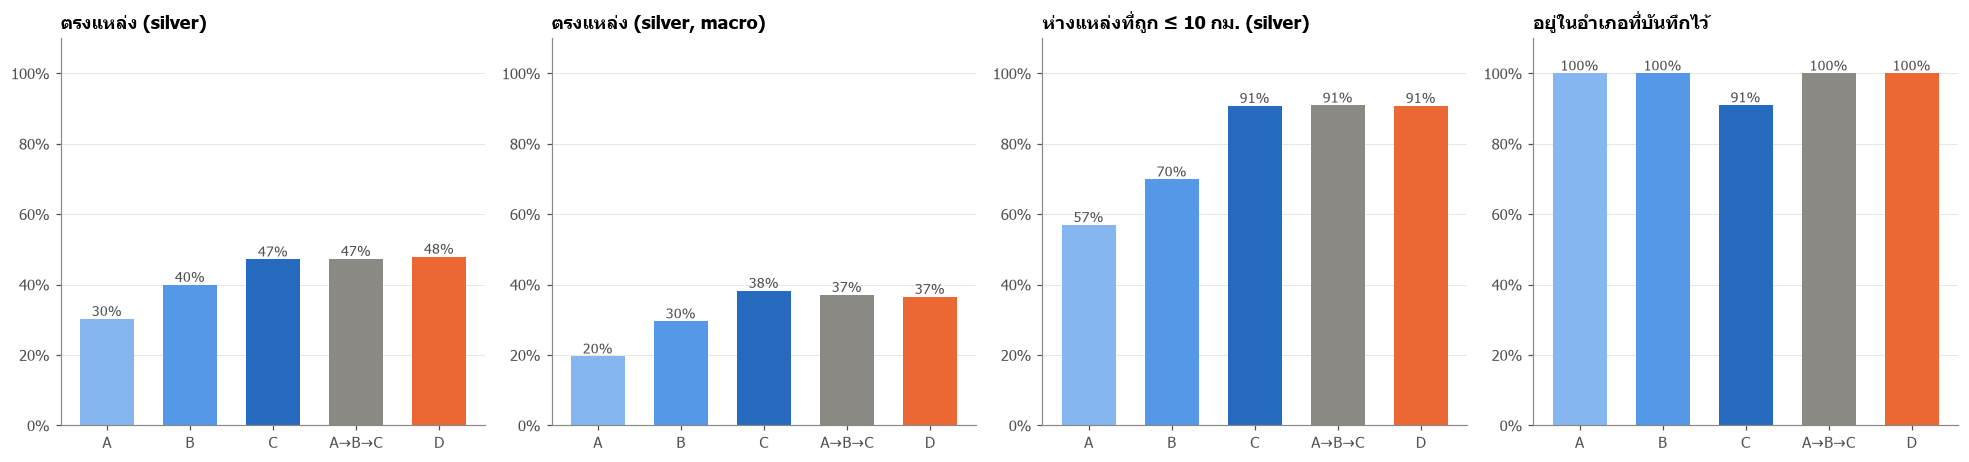

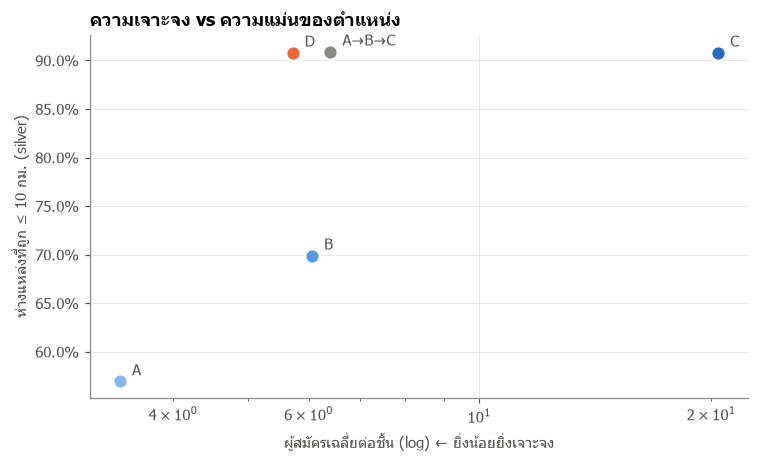

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, (col, title) in zip(axes, [("acc_ranked", "ตรงแหล่ง (silver)"),
                                   ("macro_acc_ranked", "ตรงแหล่ง (silver, macro)"),
                                   ("within_10km", "ห่างแหล่งที่ถูก ≤ 10 กม. (silver)"),
                                   ("loc_consistency", "อยู่ในอำเภอที่บันทึกไว้")]):
    v = results[col]
    ax.bar(v.index, v.values, color=[METHOD_COLOR[m] for m in v.index], width=0.65)
    for x, y in enumerate(v.values):
        ax.text(x, y, f"{y:.0%}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_ylim(0, 1.1)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(7, 4.3))
for m in order:
    r = results.loc[m]
    ax.scatter(r.cand_mean, r.within_10km, s=90, color=METHOD_COLOR[m], edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(m, (r.cand_mean, r.within_10km), textcoords="offset points", xytext=(8, 4), fontsize=10, color=INK)
ax.set_xscale("log")
ax.set_xlabel("ผู้สมัครเฉลี่ยต่อชิ้น (log) ← ยิ่งน้อยยิ่งเจาะจง")
ax.set_ylabel("ห่างแหล่งที่ถูก ≤ 10 กม. (silver)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("ความเจาะจง vs ความแม่นของตำแหน่ง")
plt.tight_layout()

### ความถูกต้องแยกตามระดับที่ match (วิธี D)

ใช้กำหนดระดับความเชื่อมั่นของผลลัพธ์สุดท้าย

In [15]:
topD = pick_top(cands["D"]).merge(cands["D"][["fossil_id", "OBJECTID", "match_level"]], on=["fossil_id", "OBJECTID"])
lvl = topD.drop_duplicates("fossil_id").set_index("fossil_id").match_level
n_top = topD.groupby("fossil_id").size()
rows = []
for fid, true in TRUE.items():
    if fid in lvl.index:
        ts = set(topD.loc[topD.fossil_id.eq(fid), "OBJECTID"])
        rows.append((lvl[fid], len(ts & true) / len(ts)))
by_level = pd.DataFrame(rows, columns=["match_level", "acc"]).groupby("match_level").acc.agg(["size", "mean"])
by_level.columns = ["silver ตัวอย่าง", "acc_ranked"]
by_level.join(lvl.value_counts().rename("ตัวอย่างทั้งหมด")).reindex(["tambon", "locality", "district", "province"]).style.format({"acc_ranked": "{:.0%}"})

,silver ตัวอย่าง,acc_ranked,ตัวอย่างทั้งหมด
match_level,,,
tambon,589,53%,3811
locality,195,34%,414
district,106,62%,2522
province,67,22%,1106


### silver labels พลาดตรงไหน

ดูตัวอย่าง silver ที่วิธี D **ไม่มี**แหล่งที่ถูกอยู่ในผู้สมัครเลย เทียบตำแหน่งที่ตัวอย่างบันทึกไว้กับตำแหน่งของ "แหล่งที่ถูก"

In [16]:
cs = cands["D"].groupby("fossil_id").OBJECTID.agg(set)
lv = cands["D"].drop_duplicates("fossil_id").set_index("fossil_id")[["match_level"]]
miss = [f for f, t in TRUE.items() if not (cs.get(f, set()) & t)]
mm = fl[fl.fossil_id.isin(miss)].join(lv, on="fossil_id").merge(silver[["fossil_id", "label_group", "true_sites"]], on="fossil_id")
mm["แหล่งที่ถูก (อำเภอ/ตำบล)"] = mm.true_sites.map(
    lambda ts: "; ".join(sorted({f"{r.district_key}/{r.tambon_key}" for r in sites[sites.OBJECTID.isin(ts)].itertuples()})))
print(f"D พลาด {len(mm)} จาก {len(TRUE)} silver ({len(mm) / len(TRUE):.1%})")
mm.groupby(["label_group", "district_key", "tambon_key", "match_level", "แหล่งที่ถูก (อำเภอ/ตำบล)"], dropna=False).size().rename("ตัวอย่าง").to_frame()

D พลาด 32 จาก 957 silver (3.3%)


ตัวอย่าง
label_group                  district_key    tambon_key    match_level แหล่งที่ถูก (อำเภอ/ตำบล)          
Agathiceras | เลย            ภูกระดึง        ศรีฐาน        district    เมืองเลย/เมือง                   1
                             วังสะพุง        NaN           district    เมืองเลย/เมือง                   1
Daonella | สงขลา             นาทวี           NaN           district    จะนะ/จะโหนง                      1
Ferganoceratodus | กาฬสินธุ์ คำม่วง          ดินจี่        tambon      กุฉินารายณ์/เหล่าใหญ่            7
Hustedia | เพชรบูรณ์         รอตรวจสอบ       บนเขาหินกลิ้ง locality    วิเชียรบุรี/สระประดู่            1
Isanichthys | กาฬสินธุ์      คำม่วง          ดินจี่        tambon      กุฉินารายณ์/เหล่าใหญ่            4
Joannites | ลำปาง            แม่เมาะ         แม่เมาะ       tambon      แม่เมาะ/บ้านดง                   1
Linoproductus | กระบี่       อ่าวลึก         อ่าวน้ำ       locality    อ่าวลึก/เขาใหญ่                  1
                                             แหลมสัก       tambon      อ่าวลึก/เขาใหญ่                  1
                             เขาพนม          หน้าเขา       tambon      อ่าวลึก/เขาใหญ่                  2
                             เมืองกระบี่     NaN           district    อ่าวลึก/เขาใหญ่                  1
Siamodon | นครราชสีมา        เมืองนครราชสีมา สุรนารี       tambon      เมืองนครราชสีมา/โคกกรวด          2
Spinomartinia | กระบี่       อ่าวลึก         แหลมสัก       tambon      อ่าวลึก/เขาใหญ่                  1
                             เมืองกระบี่     อ่าวนาง       tambon      อ่าวลึก/เขาใหญ่                  6
Thailandium | สตูล           เมืองสตูล       เกาะตะรุเตา   tambon      เมืองสตูล/เกาะสาหร่าย            1
Thaiodus | นครราชสีมา        เมืองนครราชสีมา โคกกรวด       tambon      เมืองนครราชสีมา/สุรนารี          1

เกือบทุกกรณีที่ D พลาด ตัวอย่าง**บันทึกตำบลไว้ชัดเจน**แต่เป็นคนละตำบลกับ "แหล่งที่ถูก" ตาม silver
เช่น *Spinomartinia* ที่บันทึกว่ามาจาก "อ่าวนาง" แต่ silver ชี้ไปที่แหล่งในตำบลเขาใหญ่ เพราะแหล่งนั้นบังเอิญเขียนชื่อสกุลไว้ในคำบรรยาย
ซากชนิดเดียวกันพบได้หลายแหล่ง กรณีเหล่านี้จึงน่าจะเป็น**ความผิดพลาดของ silver label** มากกว่าของ D
วิธี C ทำคะแนน silver ได้ดีในกรณีนี้เพราะ**ไม่สนตำแหน่งที่บันทึก** แล้วเลือกจากคำบรรยายอย่างเดียว
ซึ่งได้เปรียบจากอคติของ silver labels โดยตรง

## 7. เลือกวิธีที่ดีที่สุด

ใช้หลายเกณฑ์ร่วมกัน ไม่ใช้ silver อย่างเดียว เพราะ silver มีอคติตามที่เห็นด้านบน
จัดอันดับแต่ละวิธีในแต่ละเกณฑ์ (1 = ดีสุด) แล้วเฉลี่ยอันดับ

In [17]:
# True = ยิ่งต่ำยิ่งดี | ไม่ใช้ dist_km_median เพราะทุกวิธีได้ 1.0 กม. เท่ากัน (แหล่งที่เสมอกันส่วนใหญ่อยู่ห่างกัน ~1 กม.)
CRITERIA = {"coverage": False, "cand_mean": True, "acc_ranked": False, "macro_acc_ranked": False,
            "within_10km": False, "loc_consistency": False}
ranks = pd.DataFrame({c: results[c].rank(ascending=asc, method="min") for c, asc in CRITERIA.items()})
ranks["mean_rank"] = ranks.mean(axis=1)
best = ranks.mean_rank.idxmin()
print("วิธีที่อันดับเฉลี่ยดีที่สุด:", best)
display(ranks.sort_values("mean_rank"))
lv_counts = pd.DataFrame({m: cands[m].drop_duplicates("fossil_id").match_level.value_counts() for m in ["A→B→C", "D"]}).reindex(
    ["tambon", "locality", "district", "province"]).fillna(0).astype(int)
print("ระดับที่ match: cascade vs fuzzy")
lv_counts.assign(ต่าง=lambda d: d["D"] - d["A→B→C"])

วิธีที่อันดับเฉลี่ยดีที่สุด: D


,coverage,cand_mean,acc_ranked,macro_acc_ranked,within_10km,loc_consistency,mean_rank
D,1.0,2.0,1.0,3.0,2.0,1.0,1.666667
A→B→C,1.0,4.0,2.0,2.0,1.0,1.0,1.833333
C,1.0,5.0,3.0,1.0,2.0,5.0,2.833333
B,4.0,3.0,4.0,4.0,4.0,1.0,3.333333
A,5.0,1.0,5.0,5.0,5.0,1.0,3.666667


ระดับที่ match: cascade vs fuzzy


,A→B→C,D,ต่าง
match_level,,,
tambon,3750,3811,61
locality,0,414,414
district,2591,2522,-69
province,1512,1106,-406


### สรุป: เลือก **วิธี D (Fuzzy hierarchical) + ตัวจัดอันดับ**

| วิธี | ข้อดี | ข้อเสีย |
|---|---|---|
| **A** ตำบล | ผู้สมัครน้อยสุด (3.4) และกลุ่มซากตรงกันสูงสุด (85%) | ครอบคลุมแค่ **44%** เพราะตำบลหายหรือสะกดต่าง |
| **B** อำเภอ | ครอบคลุม 74% | ผู้สมัคร 6 แหล่งต่อชิ้น และหลุดตัวอย่างที่ไม่มีอำเภอ |
| **C** จังหวัด | ครอบคลุม 92% และ silver macro สูงสุด (38%) | ผู้สมัคร **20 แหล่ง**ต่อชิ้น แถวหลัง merge 160k และ **9% เลือกแหล่งนอกอำเภอที่ตัวอย่างบันทึกไว้** (ขัดกับข้อมูล) คะแนน silver สูงเพราะอคติของ silver labels |
| A→B→C | ครอบคลุม 92% และเคารพตำแหน่งที่บันทึก 100% | ถอยไประดับจังหวัดง่ายเมื่อชื่อสะกดต่างหรือใส่ชื่อสถานที่แทนอำเภอ |
| **D** fuzzy | ครอบคลุม 92%, ผู้สมัครน้อยสุดในกลุ่มที่ครอบคลุมเต็ม (5.7), ตรงแหล่ง silver สูงสุด (48%), ห่างแหล่งที่ถูก ≤ 10 กม. 91%, เคารพตำแหน่งที่บันทึก 100% | macro ต่ำกว่า C/cascade เล็กน้อย, ตรงแหล่งได้ราวครึ่งเดียว |

D เทียบกับ cascade ตัวเลข silver ต่างกันเล็กน้อย ข้อได้เปรียบหลักของ D คือย้ายตัวอย่างไป**ระดับที่ละเอียดขึ้น** (ตารางด้านบน):
ประมาณ 400 ชิ้นที่ cascade ต้องถอยไประดับจังหวัด D หาแหล่งเจอจากชื่อสถานที่ (`ภูเวียง`, `ภูน้อย`) และแก้คำสะกดผิดของตำบลได้อีกหลายสิบชิ้น

**ข้อควรรู้**: การ "ตรงแหล่ง" ได้ราวครึ่งเดียวไม่ได้แปลว่าตำแหน่งผิด ส่วนใหญ่เป็นเพราะ**ตำบลเดียวมีหลายแหล่งที่บรรยายซากแบบเดียวกัน**
(เช่น แหล่งไดโนเสาร์หลายจุดในตำบลกุดหว้า) ข้อมูลในทะเบียนไม่พอจะแยก ระยะคลาดเคลื่อนจริงส่วนใหญ่จึงอยู่ราว 1 กม.

## 8. สร้างชุดข้อมูลรวม

ใช้วิธี D + ตัวจัดอันดับ แล้วเลือกแหล่งอันดับ 1 ต่อชิ้น (ถ้าเสมอ เลือก OBJECTID น้อยสุด และบันทึก `n_top`)
ระดับความเชื่อมั่น `confidence`:
- **high**: match ระดับตำบลหรือชื่อสถานที่ และอันดับ 1 ไม่เสมอใคร
- **medium**: ตำบล/ชื่อสถานที่แต่เสมอกัน หรืออำเภอที่อันดับ 1 ไม่เสมอใคร
- **low**: อำเภอที่เสมอกัน หรือระดับจังหวัด
- **none**: ไม่ได้แหล่ง

ไฟล์ที่บันทึก
- `data/processed/fossil_list_merged.csv`: ตัวอย่างทุกชิ้น + แหล่งที่เลือก + คอลัมน์ความเชื่อมั่น
- `data/processed/specimen_site_candidates.csv`: คู่ผู้สมัครทั้งหมดของวิธี D พร้อมคะแนน (สำหรับตรวจทาน)
- `data/processed/sites_with_specimen_counts.geojson`: แหล่งพร้อมจำนวนตัวอย่างที่เชื่อมได้
  `n_specimens` แบ่งน้ำหนักกรณีเสมอ (เสมอ k แหล่ง ได้แหล่งละ 1/k), `n_high` นับเฉพาะความเชื่อมั่น high, `n_any_tied` นับทุกชิ้นที่แหล่งนี้อยู่ในกลุ่มอันดับ 1

กรณีเสมอ ไฟล์รวมจะเลือก OBJECTID น้อยสุดไว้ใน `site_*` เพื่อให้ได้พิกัดหนึ่งจุด แต่ระบุทุกแหล่งที่เสมอไว้ใน `tied_site_ids`
**อย่านับจำนวนตัวอย่างต่อแหล่งจาก `site_OBJECTID` โดยตรง** ให้ใช้ `n_specimens` ในไฟล์ GeoJSON แทน

In [18]:
cD = cands["D"].join(SCORES, on=["fossil_id", "OBJECTID"])
cD["rank"] = cD.groupby("fossil_id").score.rank(method="min", ascending=False).astype(int)
chosen = (cD[cD["rank"].eq(1)].sort_values(["fossil_id", "OBJECTID"])
          .assign(n_top=lambda d: d.groupby("fossil_id").OBJECTID.transform("size"))
          .drop_duplicates("fossil_id"))
chosen = chosen.merge(cD.groupby("fossil_id").size().rename("n_candidates"), on="fossil_id")
tied = cD[cD["rank"].eq(1)].assign(weight=lambda d: 1 / d.groupby("fossil_id").OBJECTID.transform("size"))
chosen = chosen.merge(tied.groupby("fossil_id").OBJECTID.agg(lambda s: ";".join(map(str, sorted(s)))).rename("tied_site_ids"), on="fossil_id")


def confidence(r):
    fine = r.match_level in ("tambon", "locality")
    if fine and r.n_top == 1:
        return "high"
    if fine or (r.match_level == "district" and r.n_top == 1):
        return "medium"
    return "low"


chosen["confidence"] = chosen.apply(confidence, axis=1)

site_cols = ["OBJECTID", "SITE_CODE", "NAME_TH", "PROVINCE", "DISTRICT", "TAMBON", "LOCALITY", "longitude", "latitude",
             "GEO_GROUP", "FORMATION", "PERIODFROM", "FOS_DES_TH", "IMPORTA_TH"]
site_part = sites[site_cols].rename(columns=lambda c: "site_" + c)
merged = (fl.drop(columns=["terms"])
          .merge(chosen[["fossil_id", "OBJECTID", "match_level", "fuzzy_note", "n_candidates", "n_top", "tied_site_ids",
                         "score", "kw", "grp", "adm", "confidence"]],
                 on="fossil_id", how="left")
          .merge(site_part, left_on="OBJECTID", right_on="site_OBJECTID", how="left")
          .drop(columns=["OBJECTID"]))
merged["site_OBJECTID"] = merged.site_OBJECTID.astype("Int64")  # ไม่ให้กลายเป็นทศนิยมเพราะมีค่าว่าง
merged["match_level"] = merged.match_level.fillna("none")
merged["confidence"] = merged.confidence.fillna("none")
assert len(merged) == N and merged.fossil_id.is_unique

merged.to_csv(OUT / "fossil_list_merged.csv", index=False, encoding="utf-8-sig")
cD.merge(sites[["OBJECTID", "NAME_TH"]], on="OBJECTID").sort_values(["fossil_id", "rank"]).to_csv(
    OUT / "specimen_site_candidates.csv", index=False, encoding="utf-8-sig")

# จำนวนต่อแหล่งแบบแบ่งน้ำหนัก: ตัวอย่างที่เสมอกัน k แหล่ง ให้แต่ละแหล่ง 1/k (ไม่โยนทั้งหมดให้แหล่งที่ถูกเลือกตอนตัดสินเสมอ)
counts = pd.DataFrame({
    "n_specimens": tied.groupby("OBJECTID").weight.sum().round(1),
    "n_high": chosen[chosen.confidence.eq("high")].groupby("OBJECTID").size(),
    "n_any_tied": tied.groupby("OBJECTID").size(),
})
taxon = tied.merge(fl[["fossil_id", "com_name"]], on="fossil_id").groupby("OBJECTID").com_name.agg(
    lambda s: s.mode().iat[0] if s.notna().any() else None).rename("top_taxon")
site_out = sites.drop(columns=["genera", "loc_text", "content_text"]).merge(counts.join(taxon), left_on="OBJECTID", right_index=True, how="left")
site_out[["n_specimens", "n_high", "n_any_tied"]] = site_out[["n_specimens", "n_high", "n_any_tied"]].fillna(0)
site_out[["n_high", "n_any_tied"]] = site_out[["n_high", "n_any_tied"]].astype(int)
site_out.to_file(OUT / "sites_with_specimen_counts.geojson", driver="GeoJSON")

print(f"บันทึก {OUT}/fossil_list_merged.csv ({len(merged):,} แถว, {merged.shape[1]} คอลัมน์)")
print(f"แหล่งที่มีตัวอย่างเชื่อมอย่างน้อย 1 ชิ้น: {(site_out.n_specimens > 0).sum()} / {len(site_out)}")
pd.crosstab(merged.match_level, merged.confidence, margins=True).reindex(["tambon", "locality", "district", "province", "none", "All"])

บันทึก ../data/processed/fossil_list_merged.csv (8,521 แถว, 39 คอลัมน์)
แหล่งที่มีตัวอย่างเชื่อมอย่างน้อย 1 ชิ้น: 438 / 518


confidence,high,low,medium,none,All
match_level,,,,,
tambon,1597,0,2214,0,3811
locality,172,0,242,0,414
district,0,834,1688,0,2522
province,0,1106,0,0,1106
none,0,0,0,668,668
All,1769,1940,4144,668,8521


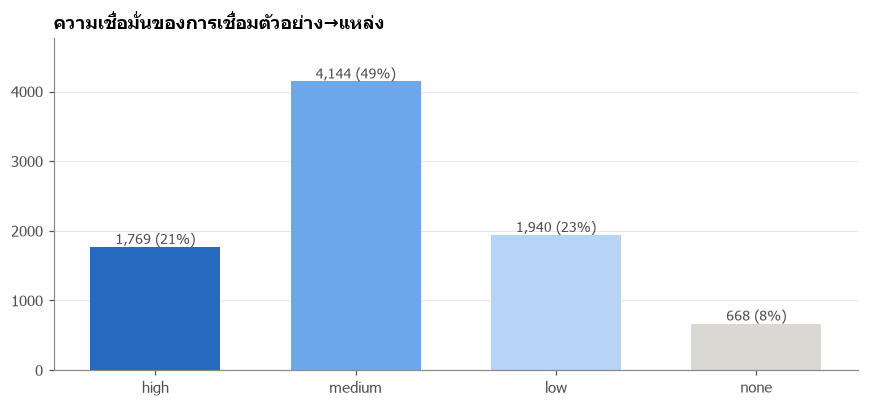

In [19]:
conf_order = ["high", "medium", "low", "none"]
conf_color = {"high": "#256abf", "medium": "#6da7ec", "low": "#b7d3f6", "none": "#d9d8d3"}
cc = merged.confidence.value_counts().reindex(conf_order)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(cc.index, cc.values, color=[conf_color[c] for c in cc.index], width=0.65)
for x, v in enumerate(cc.values):
    ax.text(x, v, f"{v:,} ({v / N:.0%})", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, cc.max() * 1.15)
ax.set_title("ความเชื่อมั่นของการเชื่อมตัวอย่าง→แหล่ง")
ax.grid(axis="x", visible=False)
plt.tight_layout()

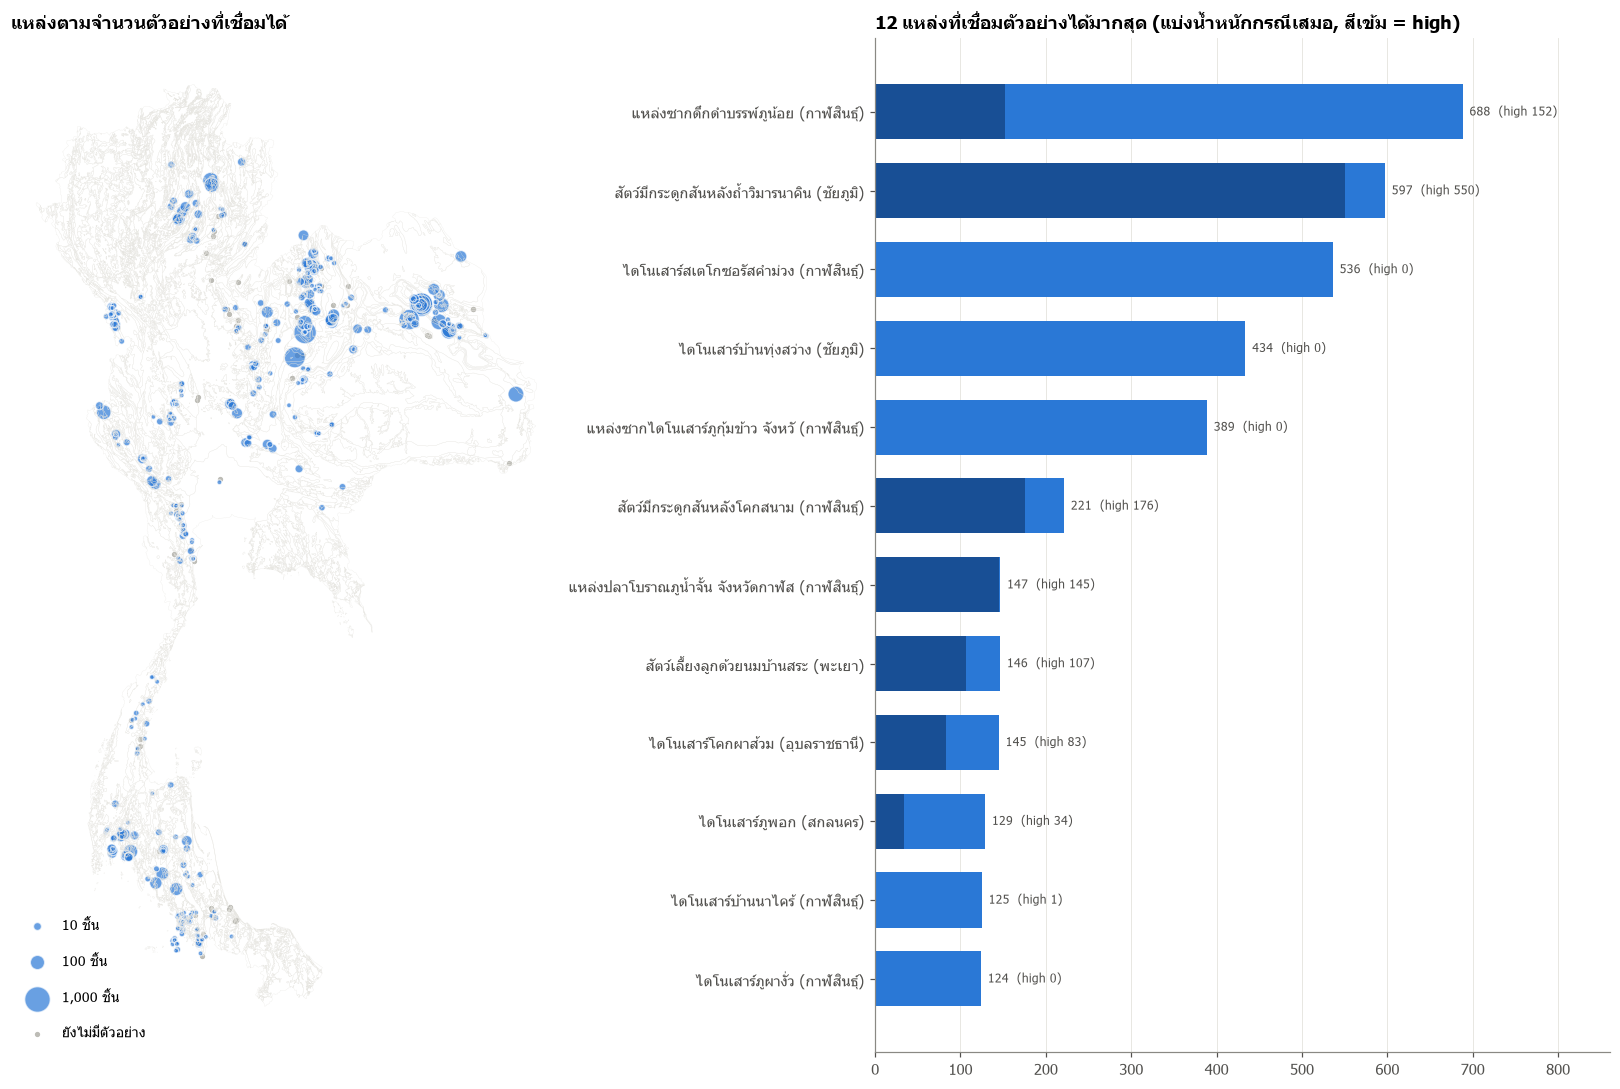

In [20]:
rock = gpd.read_file(DATA / "dmr_geology" / "rock_unit_250k.geojson")[["geometry"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
rock.boundary.plot(ax=ax, color="#e6e5e0", linewidth=0.15)
site_out[site_out.n_specimens.eq(0)].plot(ax=ax, color="#bdbcb6", markersize=6)
linked = site_out[site_out.n_specimens.gt(0)].sort_values("n_specimens", ascending=False)
linked.plot(ax=ax, color="#2a78d6", alpha=0.7, edgecolor="white", linewidth=0.8,
            markersize=np.clip(np.sqrt(linked.n_specimens) * 9, 10, 700))
for n in (10, 100, 1000):
    ax.scatter([], [], s=np.sqrt(n) * 9, color="#2a78d6", alpha=0.7, edgecolor="white", label=f"{n:,} ชิ้น")
ax.scatter([], [], s=6, color="#bdbcb6", label="ยังไม่มีตัวอย่าง")
ax.legend(loc="lower left", frameon=False, labelspacing=1.4, fontsize=9)
ax.set_axis_off()
ax.set_title("แหล่งตามจำนวนตัวอย่างที่เชื่อมได้", loc="left", fontweight="bold")

top = linked.head(12)[::-1]
axes[1].barh([f"{n[:34]} ({p})" for n, p in zip(top.NAME_TH, top.PROVINCE)], top.n_specimens, color="#2a78d6", height=0.7)
axes[1].barh([f"{n[:34]} ({p})" for n, p in zip(top.NAME_TH, top.PROVINCE)], top.n_high, color="#184f95", height=0.7)
for y, (v, h) in enumerate(zip(top.n_specimens, top.n_high)):
    axes[1].text(v + 8, y, f"{v:,.0f}  (high {h:,})", va="center", fontsize=8, color=INK)
axes[1].set_xlim(0, top.n_specimens.max() * 1.25)
axes[1].grid(axis="y", visible=False)
axes[1].set_title("12 แหล่งที่เชื่อมตัวอย่างได้มากสุด (แบ่งน้ำหนักกรณีเสมอ, สีเข้ม = high)")
plt.tight_layout()

## 9. ทดสอบความไวของเกณฑ์และน้ำหนัก

ตัวเลขในวิธี D มาจาก 2 ทาง: **เกณฑ์ตำบล 75** เลือกจากการไล่ค่าและตรวจคู่ชื่อ (หัวข้อ 3) ส่วน**เกณฑ์จังหวัด 90 อำเภอ 85 ชื่อสถานที่ 90**
และ**น้ำหนัก 0.5 / 0.3 / 0.2** ตั้งตามหลักการ — ระดับบนผิดแล้วเสียหายมากกว่าจึงใช้เกณฑ์เข้มกว่า และหลักฐานที่เจาะจงกว่า (คำในชื่อแหล่ง)
ได้น้ำหนักมากกว่าหลักฐานกว้าง (กลุ่มซาก, ชื่อเขต) — ไม่ได้ปรับจากข้อมูล เพราะ silver labels มีอคติ (หัวข้อ 6)
ส่วนนี้ตรวจว่าผลเปลี่ยนแค่ไหนเมื่อเปลี่ยนค่าเหล่านี้

- **น้ำหนัก**: ทุกชุด (kw, grp, adm) ที่เพิ่มทีละ 0.1 และรวมกันได้ 1 (66 ชุด) จัดอันดับผู้สมัครชุดเดิมของวิธี D ใหม่
- **เกณฑ์**: เปลี่ยนทีละค่า ±5 จากค่าที่ใช้ (จังหวัด 85 / 95, อำเภอ 80 / 90, ตำบล 70 / 80, ชื่อสถานที่ 85 / 95) แล้วเชื่อมใหม่ทั้งหมด
- `top1_same` = สัดส่วนตัวอย่างที่แหล่งอันดับ 1 เหมือนกับชุดที่ใช้จริงทุกแหล่ง (รวมกรณีเสมอ)

ส่วนนี้รันหลังบันทึกไฟล์ในหัวข้อ 8 แล้ว จึงไม่เปลี่ยนผลการเชื่อมโยงที่ใช้จริง

In [21]:
W0 = (0.5, 0.3, 0.2)
BASE_SCORES = SCORES.copy()
COMP = BASE_SCORES[["kw", "grp", "adm"]].copy()
KEYS = ["coverage", "cand_mean", "acc_ranked", "macro_acc_ranked", "within_10km", "loc_consistency"]


def with_weights(w):
    global SCORES
    SCORES = COMP.assign(score=COMP.kw * w[0] + COMP.grp * w[1] + COMP.adm * w[2])


def top_sets(c):
    return pick_top(c).groupby("fossil_id").OBJECTID.agg(frozenset)


def same_top(t):
    common = top0.index.intersection(t.index)
    return float((t.loc[common] == top0.loc[common]).mean())


with_weights(W0)
top0 = top_sets(cands["D"])
grid = [(a / 10, b / 10, round(1 - a / 10 - b / 10, 1)) for a in range(11) for b in range(11 - a)]
NAMED = {"ที่ใช้ 0.5 / 0.3 / 0.2": W0, "เท่ากัน 1/3": (1 / 3, 1 / 3, 1 / 3), "ไม่มี adm 0.6 / 0.4 / 0": (0.6, 0.4, 0.0),
         "kw อย่างเดียว": (1.0, 0.0, 0.0), "grp อย่างเดียว": (0.0, 1.0, 0.0), "adm อย่างเดียว": (0.0, 0.0, 1.0)}
rows = []
for name, w in [(None, w) for w in grid] + list(NAMED.items()):
    with_weights(w)
    r = evaluate(cands["D"])
    rows.append({"ชุด": name, "w_kw": w[0], "w_grp": w[1], "w_adm": w[2], **{k: r[k] for k in KEYS}, "top1_same": same_top(top_sets(cands["D"]))})
with_weights(W0)
sensW = pd.DataFrame(rows)
named = sensW.dropna(subset=["ชุด"]).set_index("ชุด").drop(columns=["coverage", "cand_mean"])
display(named.style.format({c: ("{:.2f}" if c.startswith("w_") else "{:.1%}") for c in named.columns}))
grid_all = sensW[sensW["ชุด"].isna()]
mixed = grid_all[(grid_all[["w_kw", "w_grp", "w_adm"]] > 0).all(axis=1)]
summ = pd.DataFrame({f"{lab} ({len(g)} ชุด)": g[["acc_ranked", "macro_acc_ranked", "within_10km", "loc_consistency", "top1_same"]].agg(["min", "median", "max"]).T.apply(
    lambda r: f"{r['min']:.1%} – {r['max']:.1%} (มัธยฐาน {r['median']:.1%})", axis=1) for lab, g in [("ทุกชุด", grid_all), ("ทุกส่วนมีน้ำหนัก > 0", mixed)]})
summ

,w_kw,w_grp,w_adm,acc_ranked,macro_acc_ranked,within_10km,loc_consistency,top1_same
ชุด,,,,,,,,
ที่ใช้ 0.5 / 0.3 / 0.2,0.50,0.30,0.20,48.0%,36.5%,90.8%,100.0%,100.0%
เท่ากัน 1/3,0.33,0.33,0.33,48.0%,36.5%,90.8%,100.0%,99.5%
ไม่มี adm 0.6 / 0.4 / 0,0.60,0.40,0.00,43.8%,36.3%,90.7%,100.0%,88.7%
kw อย่างเดียว,1.00,0.00,0.00,43.7%,36.3%,90.7%,100.0%,67.3%
grp อย่างเดียว,0.00,1.00,0.00,42.8%,29.9%,89.6%,100.0%,56.5%
adm อย่างเดียว,0.00,0.00,1.00,46.8%,30.1%,89.0%,100.0%,39.0%


,ทุกชุด (66 ชุด),ทุกส่วนมีน้ำหนัก > 0 (36 ชุด)
acc_ranked,42.8% – 48.0% (มัธยฐาน 47.9%),47.9% – 48.0% (มัธยฐาน 48.0%)
macro_acc_ranked,29.9% – 36.5% (มัธยฐาน 36.5%),36.5% – 36.5% (มัธยฐาน 36.5%)
within_10km,89.0% – 90.8% (มัธยฐาน 90.8%),90.8% – 90.8% (มัธยฐาน 90.8%)
loc_consistency,100.0% – 100.0% (มัธยฐาน 100.0%),100.0% – 100.0% (มัธยฐาน 100.0%)
top1_same,39.0% – 100.0% (มัธยฐาน 99.3%),97.5% – 100.0% (มัธยฐาน 99.5%)


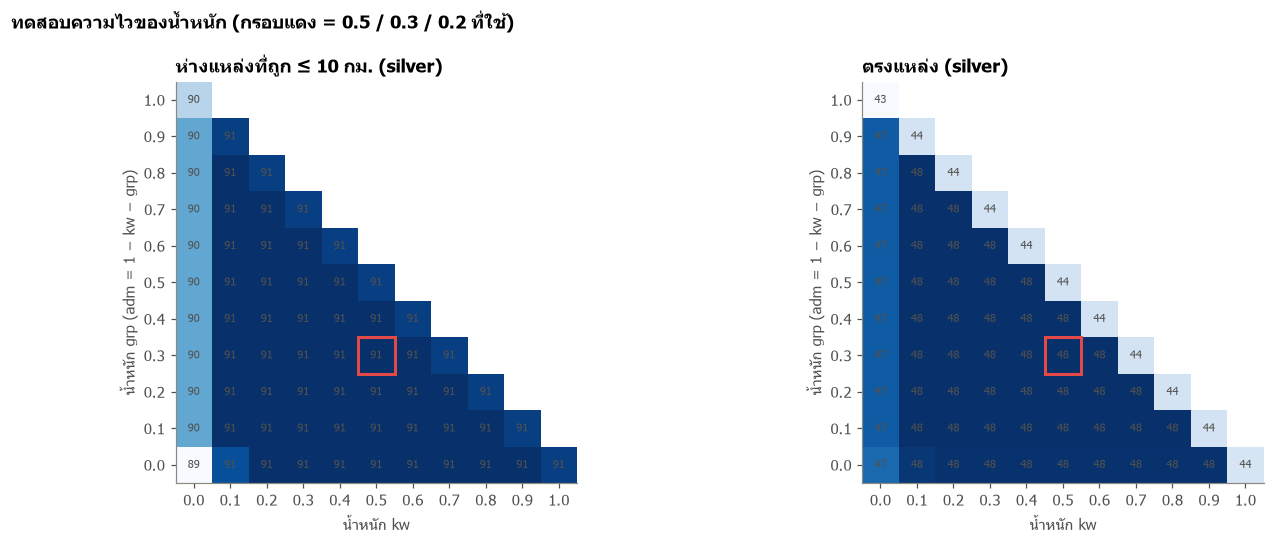

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (col, title) in zip(axes, [("within_10km", "ห่างแหล่งที่ถูก ≤ 10 กม. (silver)"), ("acc_ranked", "ตรงแหล่ง (silver)")]):
    M = grid_all.pivot(index="w_grp", columns="w_kw", values=col).sort_index(ascending=False)
    im = ax.imshow(M.values, cmap="Blues", vmin=grid_all[col].min(), vmax=grid_all[col].max())
    ax.set_xticks(range(M.shape[1]), [f"{v:.1f}" for v in M.columns])
    ax.set_yticks(range(M.shape[0]), [f"{v:.1f}" for v in M.index])
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M.values[i, j]):
                ax.text(j, i, f"{M.values[i, j] * 100:.0f}", ha="center", va="center", fontsize=7, color=INK)
    j0, i0 = list(M.columns).index(0.5), list(M.index).index(0.3)
    ax.add_patch(plt.Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False, ec="#e34948", lw=2))
    ax.set_xlabel("น้ำหนัก kw")
    ax.set_ylabel("น้ำหนัก grp (adm = 1 − kw − grp)")
    ax.set_title(title)
    ax.grid(False)
fig.suptitle("ทดสอบความไวของน้ำหนัก (กรอบแดง = 0.5 / 0.3 / 0.2 ที่ใช้)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

In [23]:
def extend_comp(c):
    # ให้คะแนนส่วนประกอบของคู่ (ตัวอย่าง, แหล่ง) ใหม่ที่เกิดจากเกณฑ์อื่น — ใช้ฟังก์ชันเดียวกับหัวข้อ 4
    global COMP
    new = c[["fossil_id", "OBJECTID"]].drop_duplicates()
    new = new[~pd.MultiIndex.from_frame(new).isin(COMP.index)]
    if new.empty:
        return
    q = new.merge(fl[["fossil_id", "terms", "f_group", "district_key", "tambon_key"]], on="fossil_id")
    q["kw"] = [kw_score(t, o) for t, o in zip(q.terms, q.OBJECTID)]
    q["kw"] = q.kw.where(q.kw >= 0.8, 0.0)
    q["grp"] = [float(SITE.at[o, g]) if isinstance(g, str) else 0.0 for g, o in zip(q.f_group, q.OBJECTID)]
    q["adm"] = [adm_score(d, t, o) for d, t, o in zip(q.district_key, q.tambon_key, q.OBJECTID)]
    COMP = pd.concat([COMP, q.set_index(["fossil_id", "OBJECTID"])[["kw", "grp", "adm"]]])


VARIANTS = {"ที่ใช้ (90 / 85 / 75 / 90)": {}, "จังหวัด 85": {"t_prov": 85}, "จังหวัด 95": {"t_prov": 95},
            "อำเภอ 80": {"t_dist": 80}, "อำเภอ 90": {"t_dist": 90}, "ตำบล 70": {"t_tamb": 70}, "ตำบล 80": {"t_tamb": 80},
            "ชื่อสถานที่ 85": {"t_loc": 85}, "ชื่อสถานที่ 95": {"t_loc": 95}}
rows = []
for name, th in VARIANTS.items():
    c = cands["D"] if not th else fuzzy_candidates(**th)
    extend_comp(c)
    with_weights(W0)
    r = evaluate(c)
    lvl = c.drop_duplicates("fossil_id").match_level.value_counts()
    rows.append({"เกณฑ์": name, **{k: r[k] for k in KEYS}, "top1_same": same_top(top_sets(c)),
                 "ระดับตำบล/ชื่อสถานที่": int(lvl.get("tambon", 0) + lvl.get("locality", 0)), "ระดับจังหวัด": int(lvl.get("province", 0))})
sensT = pd.DataFrame(rows).set_index("เกณฑ์")
SCORES = BASE_SCORES                     # คืนค่าที่ใช้จริง
sensT.style.format({**{k: "{:.1%}" for k in KEYS if k != "cand_mean"}, "cand_mean": "{:.2f}", "top1_same": "{:.1%}"})

,coverage,cand_mean,acc_ranked,macro_acc_ranked,within_10km,loc_consistency,top1_same,ระดับตำบล/ชื่อสถานที่,ระดับจังหวัด
เกณฑ์,,,,,,,,,
ที่ใช้ (90 / 85 / 75 / 90),92.2%,5.72,48.0%,36.5%,90.8%,100.0%,100.0%,4225,1106
จังหวัด 85,92.2%,5.72,48.0%,36.5%,90.8%,100.0%,100.0%,4225,1106
จังหวัด 95,92.2%,5.72,48.0%,36.5%,90.8%,100.0%,100.0%,4225,1106
อำเภอ 80,92.2%,5.72,48.0%,36.5%,90.8%,100.0%,100.0%,4225,1105
อำเภอ 90,92.2%,5.72,48.0%,36.5%,90.8%,100.0%,100.0%,4225,1106
ตำบล 70,92.2%,5.72,48.0%,36.5%,90.8%,100.0%,100.0%,4225,1106
ตำบล 80,92.2%,5.72,48.0%,36.5%,90.8%,100.0%,100.0%,4224,1106
ชื่อสถานที่ 85,92.2%,5.67,48.0%,36.5%,90.8%,100.0%,99.7%,4247,1084
ชื่อสถานที่ 95,92.2%,5.72,48.0%,36.5%,90.8%,100.0%,100.0%,4223,1108


In [24]:
# สรุปเป็นตัวเลขสำหรับรายงาน (คำนวณจากตารางด้านบน)
u = sensW[sensW["ชุด"].eq("ที่ใช้ 0.5 / 0.3 / 0.2")].iloc[0]
d = sensT.drop(index="ที่ใช้ (90 / 85 / 75 / 90)")
print(f"น้ำหนักที่ทุกส่วน > 0 ({len(mixed)} ชุด): ห่าง ≤ 10 กม. {mixed.within_10km.min():.1%}–{mixed.within_10km.max():.1%} "
      f"(ที่ใช้ {u.within_10km:.1%}), ตรงแหล่ง {mixed.acc_ranked.min():.1%}–{mixed.acc_ranked.max():.1%} (ที่ใช้ {u.acc_ranked:.1%}), "
      f"แหล่งอันดับ 1 เหมือนเดิม {mixed.top1_same.min():.1%}–{mixed.top1_same.max():.1%}")
print(f"เกณฑ์ ±5: ครอบคลุม {d.coverage.min():.1%}–{d.coverage.max():.1%} (ที่ใช้ {sensT.coverage.iloc[0]:.1%}), "
      f"ห่าง ≤ 10 กม. {d.within_10km.min():.1%}–{d.within_10km.max():.1%} (ที่ใช้ {sensT.within_10km.iloc[0]:.1%}), "
      f"แหล่งอันดับ 1 เหมือนเดิม {d.top1_same.min():.1%}–{d.top1_same.max():.1%}")

น้ำหนักที่ทุกส่วน > 0 (36 ชุด): ห่าง ≤ 10 กม. 90.8%–90.8% (ที่ใช้ 90.8%), ตรงแหล่ง 47.9%–48.0% (ที่ใช้ 48.0%), แหล่งอันดับ 1 เหมือนเดิม 97.5%–100.0%
เกณฑ์ ±5: ครอบคลุม 92.2%–92.2% (ที่ใช้ 92.2%), ห่าง ≤ 10 กม. 90.8%–90.8% (ที่ใช้ 90.8%), แหล่งอันดับ 1 เหมือนเดิม 99.7%–100.0%


## 10. ตรวจเบาะแสทางอ้อมจากชื่อสามัญ

ตัวจัดอันดับไม่ใช้ชื่อสกุลละติน เพราะ silver labels สร้างจากชื่อสกุลในคำบรรยายแหล่ง (หัวข้อ 5)
แต่ชื่อสามัญภาษาไทยบางชื่อเป็นชื่อเฉพาะของสกุล เช่น "ปลากินพืชพุทธบุตร" (*Thaiichthys*) หรือ "เอปเชียงม่วน" (*Khoratpithecus*)
และบางชื่อเขียนอยู่ในคำบรรยายแหล่งด้วย `kw` จึงอาจได้เบาะแสของคำตอบทางอ้อม

ทดสอบโดยตัด**ทุกคำ** (`com_name` / `f_type`) ที่ในทะเบียนใช้กับสกุลเดียว (นับจากตัวอย่างที่ระบุสกุลแล้ว) ออกจาก `kw` แล้วจัดอันดับผู้สมัครชุดเดิมของวิธี D ใหม่
กฎนี้ตัดคำทั่วไปบางคำด้วย (เช่น "วาฬ" "กระเบน") เพราะสกุลที่ระบุแล้วยังมีน้อย จึงเป็นการทดสอบที่เข้มกว่าความจำเป็น
ถ้าผลแทบไม่เปลี่ยน แปลว่าตัวเลขของหัวข้อ 6 ไม่ได้มาจากเบาะแสนี้

In [25]:
gen_terms = fl.dropna(subset=["genus"]).explode("terms").dropna(subset=["terms"]).groupby("terms").genus.agg(set)
SPECIFIC = {t for t, g in gen_terms.items() if len(g) == 1}
fl["terms_generic"] = fl.terms.map(lambda ts: tuple(t for t in ts if t not in SPECIFIC))
hit_ids = set(fl.fossil_id[fl.terms.map(lambda ts: any(t in SPECIFIC for t in ts))])
silver_hit = silver[silver.fossil_id.isin(hit_ids)]
print(f"คำที่ใช้กับสกุลเดียว {len(SPECIFIC)} คำ จาก {len(gen_terms)} คำ | ตัวอย่างที่ถูกตัดคำ {len(hit_ids):,} ชิ้น "
      f"| ในนั้นเป็น silver {len(silver_hit)} จาก {len(silver)} ชิ้น ({silver_hit.label_group.nunique()} กลุ่ม)")
n_spec = fl.dropna(subset=["genus"]).explode("terms").terms.value_counts()
print("คำที่ใช้บ่อย:", ", ".join(f"{t} ({gen_terms[t].copy().pop()}, {n_spec[t]})" for t in n_spec.index if t in SPECIFIC)[:1500])

pairs = cands["D"][["fossil_id", "OBJECTID"]].drop_duplicates().merge(fl[["fossil_id", "terms_generic"]], on="fossil_id")
kw_g = pd.Series([kw_score(t, o) for t, o in zip(pairs.terms_generic, pairs.OBJECTID)])
C_LEAK = BASE_SCORES.loc[pd.MultiIndex.from_frame(pairs[["fossil_id", "OBJECTID"]]), ["kw", "grp", "adm"]].copy()
C_LEAK["kw"] = kw_g.where(kw_g >= 0.8, 0.0).values
SCORES = C_LEAK.assign(score=0.5 * C_LEAK.kw + 0.3 * C_LEAK.grp + 0.2 * C_LEAK.adm)
r_leak, top_leak = evaluate(cands["D"]), top_sets(cands["D"])
SCORES = BASE_SCORES                     # คืนค่าที่ใช้จริง
r_base = evaluate(cands["D"])
leak = pd.DataFrame({"ที่ใช้": r_base, "ตัดคำที่ใช้กับสกุลเดียว": r_leak}).T[KEYS]
leak["top1_same"] = [1.0, same_top(top_leak)]
leak.drop(columns=["coverage", "cand_mean"]).style.format("{:.1%}")

คำที่ใช้กับสกุลเดียว 98 คำ จาก 157 คำ | ตัวอย่างที่ถูกตัดคำ 1,476 ชิ้น | ในนั้นเป็น silver 165 จาก 957 ชิ้น (6 กลุ่ม)
คำที่ใช้บ่อย: จระเข้ภูพอก (Siamosuchus, 193), วาฬ (Balaenoptera, 141), วาฬบรูด้า (Balaenoptera, 141), ปลากินพืชพุทธบุตร (Thaiichthys, 128), กวางป่า (Rusa, 76), หมูป่า (Sus, 75), หมูดึกดำบรรพ์ (Conohyus, 46), ละองละมั่ง (Rucervus, 42), ฉลามแม่น้ำ (Glyphis, 41), หมูเคราบอเนียว (Sus, 36), ลิงใบไม้ หรือ ซูริริ (Trachypithecus, 32), ลูตู่ (Trachypithecus, 32), ไดโนเสาร์นกกระจอกเทศ (Kinnareemimus, 31), เก้ง (Muntiacus, 30), นักล่าแห่งภูเวียง (Phuwiangvenator, 29), กระทิง (Bos, 28), วัวป่าอินเดีย (Bos, 28), ฉลามหัวบาตร (Carcharhinus, 27), ไฟโตซอร์ (Phytosaur, 26), เลียงผาใต้ (Capricornis, 25), กระเบน (Myliobatiformes, 24), วัวแดง (Bos, 23), หัวขโมยแห่งสยาม (Siamraptor, 22), สัตว์เคี้ยวเอื้อง (Ruminantia, 21), ควายป่า (Bubalus, 20), พลับพลึงทะเล (Crinoidea, 19), เนื้อทราย (Axis, 19), อุรังอุตังบอร์เนียว (Pongo, 19), เอไคโนเดิร์ม (Crinoidea, 18), หมีควาย (Ursus, 18), หมีดำเอเชีย

,acc_ranked,macro_acc_ranked,within_10km,loc_consistency,top1_same
ที่ใช้,48.0%,36.5%,90.8%,100.0%,100.0%
ตัดคำที่ใช้กับสกุลเดียว,48.0%,36.5%,90.8%,100.0%,99.5%


In [26]:
# ตรงแหล่งรายกลุ่ม เฉพาะกลุ่ม silver ที่มีตัวอย่างถูกตัดคำ
def acc_per_specimen(top):
    return pd.Series({f: len(top.get(f, frozenset()) & t) / len(top[f]) if f in top.index else 0.0 for f, t in TRUE.items()})


g = silver.set_index("fossil_id").label_group
by_group = pd.DataFrame({"ตัวอย่าง": g.value_counts(), "ที่ใช้": acc_per_specimen(top0).groupby(g).mean(),
                         "ตัดคำ": acc_per_specimen(top_leak).groupby(g).mean()})
by_group.loc[sorted(silver_hit.label_group.unique(), key=lambda k: -by_group.at[k, "ตัวอย่าง"])].style.format({"ที่ใช้": "{:.1%}", "ตัดคำ": "{:.1%}"})

,ตัวอย่าง,ที่ใช้,ตัดคำ
label_group,,,
Thaiichthys | กาฬสินธุ์,131,100.0%,100.0%
Ferganoceratodus | กาฬสินธุ์,23,55.7%,55.7%
Siamraptor | นครราชสีมา,22,100.0%,100.0%
Khoratpithecus | พะเยา,18,100.0%,100.0%
Siamodon | นครราชสีมา,2,0.0%,0.0%
Thaisaurus | พัทลุง,1,100.0%,100.0%


In [27]:
# สรุปเป็นตัวเลขสำหรับรายงาน
print(f"ตัดคำที่ใช้กับสกุลเดียว: ตรงแหล่ง {r_base['acc_ranked']:.1%} → {r_leak['acc_ranked']:.1%}, "
      f"macro {r_base['macro_acc_ranked']:.1%} → {r_leak['macro_acc_ranked']:.1%}, "
      f"ห่าง ≤ 10 กม. {r_base['within_10km']:.1%} → {r_leak['within_10km']:.1%}, "
      f"ตรงอำเภอที่บันทึก {r_base['loc_consistency']:.1%} → {r_leak['loc_consistency']:.1%}, "
      f"แหล่งอันดับ 1 เหมือนเดิม {same_top(top_leak):.1%}")

ตัดคำที่ใช้กับสกุลเดียว: ตรงแหล่ง 48.0% → 48.0%, macro 36.5% → 36.5%, ห่าง ≤ 10 กม. 90.8% → 90.8%, ตรงอำเภอที่บันทึก 100.0% → 100.0%, แหล่งอันดับ 1 เหมือนเดิม 99.5%


## 11. ข้อจำกัดและการใช้งานต่อ

- **ความเชื่อมั่นต่างกันมากตามระดับ**: ระดับ `province` เป็นแค่การเดาที่มีหลักการ ควรกรอง `confidence != "low"` ก่อนใช้พิกัดวิเคราะห์ระดับแหล่ง
  แต่ระดับจังหวัด/อำเภอยังใช้วิเคราะห์ภาพรวมเชิงพื้นที่ได้
- **silver labels เอนไปทางแหล่งที่มีชื่อเสียง** (แหล่งไดโนเสาร์) ความถูกต้องจริงของกลุ่มอื่นอาจต่ำกว่านี้
- **ตัวอย่างบางส่วนอาจมาจากแหล่งที่ไม่อยู่ในฐานข้อมูลแหล่ง** (เช่น สมุทรสาคร 247 ชิ้น) ซึ่งการ merge ใด ๆ ก็เชื่อมไม่ได้
- **ทางแก้ระยะยาว**: เพิ่มคอลัมน์รหัสแหล่ง (`SITE_CODE`) หรือพิกัดในทะเบียนตัวอย่างตั้งแต่ต้นทาง
- ตรวจทานคู่ที่ไม่แน่ใจได้จาก `specimen_site_candidates.csv` (เรียงตาม `rank`)